In [1]:
%matplotlib widget

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from stompy.io.local import noaa_coops

import numpy as np

In [3]:
# Mooring data:
mooring_csv="../Kd_2022/L2/SHL_all_data_L2.csv"
df_mooring = pd.read_csv(mooring_csv)
del df_mooring['Unnamed: 0']
df_mooring['time'] = pd.to_datetime(df_mooring['dt'])
df_mooring['time'] = df_mooring.time.values # should get back to UTC

# dt has the time zone in it, and .values should get a UTC timestamp, ready for comparison to model output
df_mooring = df_mooring.iloc[(df_mooring.time.values>np.datetime64("2022-08-01")) & (df_mooring.time.values<np.datetime64("2022-09-10")),:]

In [10]:
# Add depth from Alameda - should also be UTC
ds=noaa_coops.coops_dataset(9414750, # Alameda
                            np.datetime64("2022-07-31"),np.datetime64("2022-09-12"),
                            ['water_level'],cache_dir='cache')


In [18]:
ds

<xarray.Dataset>
Dimensions:      (station: 1, time: 10320)
Coordinates:
  * station      (station) object '9414750'
  * time         (time) datetime64[ns] 2022-07-31 ... 2022-09-11T23:54:00
Data variables:
    name         (station) object ...
    lat          (station) float64 ...
    lon          (station) float64 ...
    water_level  (station, time) float64 1.314 1.296 1.267 ... 1.049 1.003 0.958

In [25]:
from stompy import utils


In [5]:
df_mooring.columns

Index(['dt', 'Datetime', 'BGA_PC_RFU', 'BGA_PC_microgL', 'BGA_PC_raw',
       'Battery_V', 'Cable_pwr_V', 'Chla_RFU', 'Chla_microgL', 'Chla_raw',
       'Cond_microScm', 'DO_PercSat', 'DO_mgL', 'DO_mgL_QAQC_flag', 'Depth_m',
       'Fault_code', 'P_dbar', 'P_psi', 'Pwr_mW_BGA', 'Pwr_mW_CT', 'Pwr_mW_DO',
       'Pwr_mW_P', 'Pwr_mW_Turb', 'Pwr_mW_Wiper', 'Pwr_mW_fDOM', 'SBE_or_EXO',
       'S_PSU', 'SpCond_QAQC_code', 'SpCond_QAQC_flag', 'SpCond_microScm',
       'TDS_mgL', 'TSS_mgL', 'T_QAQC_code', 'T_QAQC_flag', 'T_degC',
       'T_degC_BGA', 'T_degC_DO', 'T_degC_P', 'T_degC_Turb', 'T_degC_fDOM',
       'Turb', 'Turb_FNU', 'Turb_NTU', 'Turb_TSS', 'Turb_raw', 'Unnamed_0',
       'Vert_pos', 'Wiper_curr_mA', 'Wiper_parking_retries', 'Wiper_pos',
       'fDOM_QSU', 'fDOM_RFU', 'fDOM_raw', 'nLF_Cond_microScm', 'pH',
       'Cond_QAQC_flag', 'DO_percsat_QAQC_flag', 'time'],
      dtype='object')

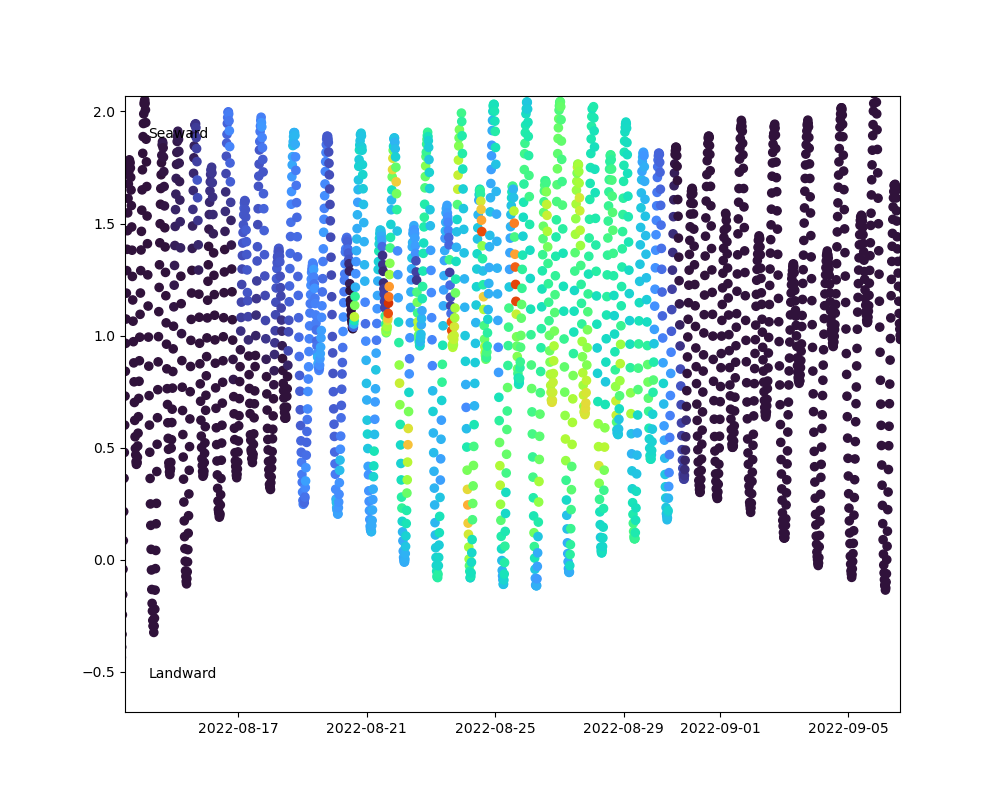

In [64]:
fig,ax = plt.subplots(figsize=(10,8))

df_mooring['wse_alameda'] = np.interp( utils.to_dnum(df_mooring.time.values) + 7/24., # -5/24 not terrible. +7/24 decent
                                       utils.to_dnum(ds.time.values), ds['water_level'].isel(station=0))

scat=ax.scatter(df_mooring.time, df_mooring.wse_alameda, 35, df_mooring.Chla_microgL, cmap='turbo',clim=[10,150])
#scat=ax.scatter(df_mooring.time, df_mooring.wse_alameda, 35, df_mooring.S_PSU, cmap='turbo',clim=[32.5,33.5])
ax.text(0.03,0.95,"Seaward",transform=ax.transAxes,va='top')
ax.text(0.03,0.05,"Landward",transform=ax.transAxes,va='bottom')

ax.axis((19217.46777721108,
 19241.610190944746,
 -0.6783904208778223,
 2.0686970677600978)) ;

In [30]:
ax.axis()


(19217.46777721108,
 19241.610190944746,
 -0.6783904208778223,
 2.0686970677600978)